In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from datetime import datetime, timedelta
import numpy as np

In [3]:
df = pd.read_csv('../preprocess/parking_time_series_with_features.csv', delimiter=',')

df['Time'] = pd.to_datetime(df['Time'])
df.set_index('Time', inplace=True)
df.sort_index(inplace=True)


In [8]:
end_date = datetime(2022, 1, 1)

train_data = df[df.index < end_date]
test_data = df[df.index >= end_date]

train_data.index = pd.DatetimeIndex(train_data.index.values, freq=train_data.index.inferred_freq)


In [13]:
# Define ARIMA model parameters (p, d, q)
p = 3  
d = 1  
q = 2  

model = ARIMA(train_data['Parkings'], order=(p, d, q))
arima_results = model.fit()


/Users/visjostr/school/parking-prediction/.venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


118070
                     Parkings  day_of_year  weekday  hour  is_holiday
Time                                                                 
2022-01-01 00:00:00        78            1        6     0           1
2022-01-01 00:01:00        77            1        6     0           1
2022-01-01 00:02:00        77            1        6     0           1
2022-01-01 00:03:00        77            1        6     0           1
2022-01-01 00:04:00        76            1        6     0           1
...                       ...          ...      ...   ...         ...
2022-01-14 23:56:00         1           14        5    23           0
2022-01-14 23:57:00         1           14        5    23           0
2022-01-14 23:58:00         1           14        5    23           0
2022-01-14 23:59:00         1           14        5    23           0
2022-01-15 00:00:00         1           15        6     0           0

[20161 rows x 5 columns]
2022-01-01 00:00:00    77.994511
2022-01-01 00:01:00    7

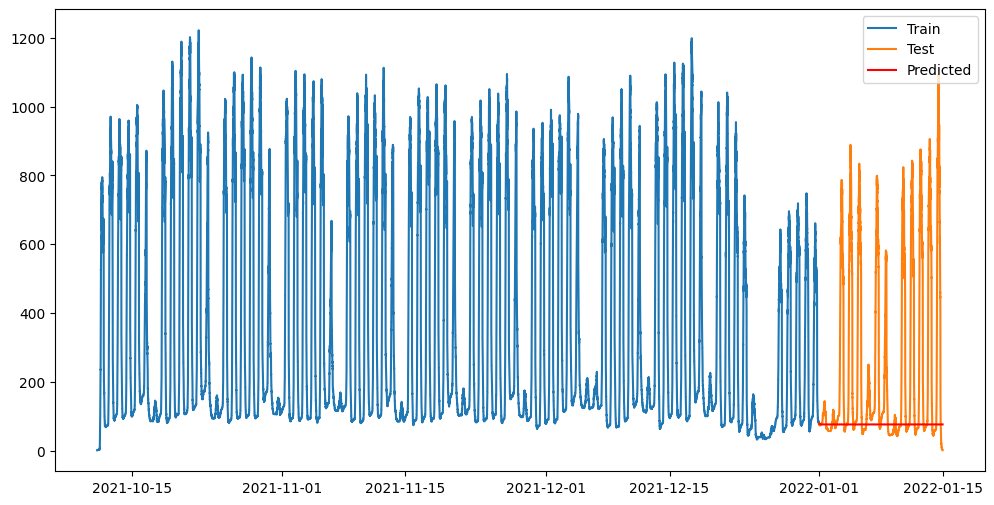

In [18]:
# Predict using the fitted model
predictions = arima_results.predict(start=test_data.index[0], end=test_data.index[-1], dynamic=False)

print(train_data)
print(test_data)
print(predictions)

# Plot the actual vs predicted values
plt.figure(figsize=(12, 6))
plt.plot(train_data.index, train_data['Parkings'], label='Train')
plt.plot(test_data.index, test_data['Parkings'], label='Test')
plt.plot(test_data.index, predictions, label='Predicted', color='red')
plt.legend()
plt.show()
